# Part 2: Check the estimates

Replay `traces/azure_conversation.csv` in Vidur (vLLM, one simulated A100-80GB), compare it with your Part 1 predictions, then look at what Part 1 could not see: the time between output tokens. Run from the repo root:

```bash
QPS=5.53 bash scripts/run_default.sh traces/azure_conversation.csv
```

In [5]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
if not (ROOT / "traces").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from analysis.replay import load_run
from analysis.workload import kv_in_use, load_trace, predict_queue_wait

WAIT_TARGET_S = 2.0    # P99 wait under 2 s (Part 1)
TBT_TARGET_S = 0.100   # P99 time between tokens under 100 ms
BIN_S = 30.0

trace = load_trace(ROOT / "traces" / "azure_conversation.csv")
predicted_wait = predict_queue_wait(trace)
predicted_kv = kv_in_use(trace, predicted_wait, BIN_S)

RUN = ROOT / "simulator_output" / "2026-10-27_18-18-24-560244"   # your vLLM run
run = load_run(RUN, trace)
req, kv = run["requests"], run["kv"]

## Predicted vs measured

                                 predicted         Vidur
P99 wait (s)                          72.1         128.8
longest stretch above 2 s      1192-2272 s   1340-2491 s
requests waiting over 2 s              36%           41%
peak KV cache (GiB)                   26.7          23.8


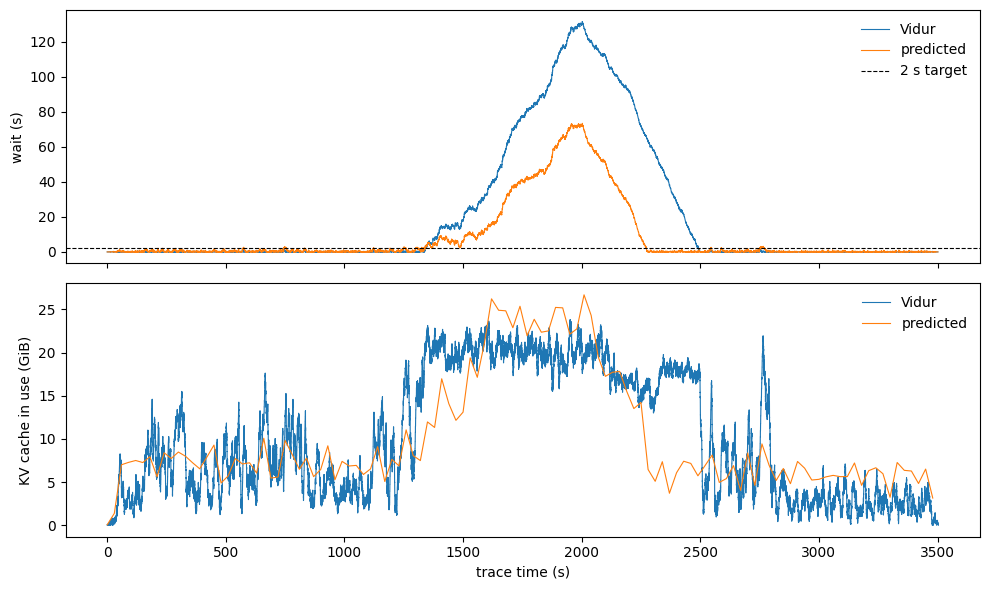

In [6]:
t = req.arrived_at.to_numpy()

def longest_late_stretch(wait, merge_gap_s=60.0):
    """Longest time range where requests wait over the target (gaps under a minute merged)."""
    late = t[wait > WAIT_TARGET_S]
    if len(late) == 0:
        return "never"
    breaks = np.flatnonzero(np.diff(late) > merge_gap_s)
    starts, ends = np.r_[late[0], late[breaks + 1]], np.r_[late[breaks], late[-1]]
    i = np.argmax(ends - starts)
    return f"{starts[i]:.0f}-{ends[i]:.0f} s"

print(f"{'':28s}{'predicted':>14s}{'Vidur':>14s}")
print(f"{'P99 wait (s)':28s}{np.quantile(predicted_wait, .99):14.1f}{req.wait.quantile(.99):14.1f}")
print(f"{'longest stretch above 2 s':28s}{longest_late_stretch(predicted_wait):>14s}{longest_late_stretch(req.wait.to_numpy()):>14s}")
print(f"{'requests waiting over 2 s':28s}{np.mean(predicted_wait > WAIT_TARGET_S):14.0%}{np.mean(req.wait > WAIT_TARGET_S):14.0%}")
print(f"{'peak KV cache (GiB)':28s}{predicted_kv.kv_gib.max():14.1f}{kv.kv_gib.max():14.1f}")

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax0.plot(t, req.wait, label="Vidur", linewidth=0.8)
ax0.plot(t, predicted_wait, label="predicted", linewidth=0.8)
ax0.axhline(WAIT_TARGET_S, color="k", linestyle="--", linewidth=0.8, label="2 s target")
ax0.set_ylabel("wait (s)")
ax0.legend(frameon=False)
ax1.plot(kv.time, kv.kv_gib, label="Vidur", linewidth=0.8)
ax1.plot(predicted_kv.bin_start, predicted_kv.kv_gib, label="predicted", linewidth=0.8)
ax1.set_ylabel("KV cache in use (GiB)")
ax1.set_xlabel("trace time (s)")
ax1.legend(frameon=False)
fig.tight_layout()
plt.show()

## Time between tokens

time between tokens: P50 17 ms   P90 131 ms   P99 553 ms   longest 6.6 s


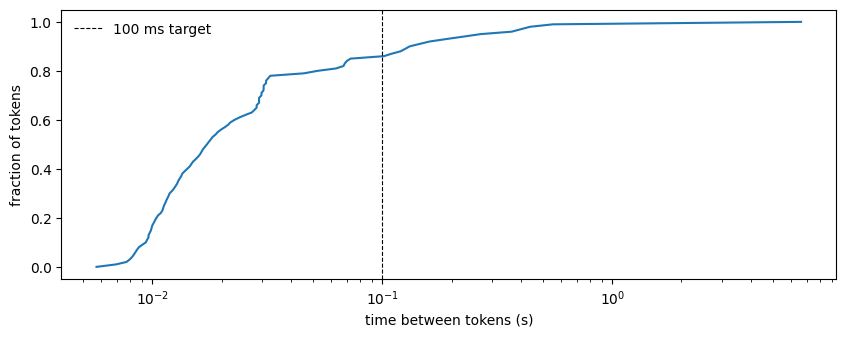

In [7]:
tbt = run["tbt"].set_index("percentile").seconds
print(f"time between tokens: P50 {tbt[50]*1e3:.0f} ms   P90 {tbt[90]*1e3:.0f} ms   P99 {tbt[99]*1e3:.0f} ms   longest {tbt[100]:.1f} s")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(tbt.to_numpy(), tbt.index / 100)
ax.axvline(TBT_TARGET_S, color="k", linestyle="--", linewidth=0.8, label="100 ms target")
ax.set_xscale("log")
ax.set_xlabel("time between tokens (s)")
ax.set_ylabel("fraction of tokens")
ax.legend(frameon=False)
plt.show()

## Questions

**Q1.** Compare your Part 1 predictions with Vidur: P99 wait, the longest stretch above the 2 s target, and peak KV-cache memory. Which held and which did not? For any that missed, say what the Part 1 model left out.

**Your answer:**

| Metric | Predicted | Simulated |
|---|---|---|
| P99 | 72.1 ms | 128.8 ms |
| Longest stretch | 1192-2272 s | 1340-2491 s |
| Peak KV cache mem | 26.7 GB| 23.8 GB |

The longest stretch was fairly accurate, at least in terms of the rough area (the middle of the trace) and the duration of the stretch.
However, the peak KV cache memory and P99 wait were a bit off, though the KV cache prediction was not off my much.

**Q2.** The target for time between tokens is **P99 under 100 ms**. Does vLLM meet it? Report the P50, P99, and longest time between tokens. What does the longest one mean for a user reading the answer?

**Your answer:**
No, it did not meet the target.

P50: 17ms\
P99: 553ms\
longest: 6.6s

The longest time between token means that someone had to wait 6.6 seconds for a token after a series of tokens had already been sent. So in the middle of the response, the user experienced a pretty long waiting time as the response was streaming.

**Q3.** What causes the longest gaps between tokens you found in Q2? Read `_get_next_batch` in `vidur/scheduler/replica_scheduler/vllm_replica_scheduler.py`: when new requests are waiting, what goes into the next iteration, and what has to wait?

**Your answer:**
The longest gaps between tokens are caused by the scheduling between new and old requests and the prefill computation of new requests. Because new requests are prioritized, old requests that are in the middle of decode are going to be blocked by requests that need to do prefill computation, which is expensive. The preempted old requests that are in the middle of generating their outputs then have to wait until the next iteration, which can cause longer TBT.

**Q4.** Part 3 fixes this by capping each iteration at a token budget C: every running request gets its one token, and waiting prompts fill the rest of the budget in chunks. One pass with C tokens (decode and prompt tokens together) takes about **6 ms + C × 78 µs** (Vidur's measured prefill time). Predict the P99 time between tokens for C = 256, 512, and 2048. Which meet the 100 ms target? What happens to the fixed 6 ms per pass, and so to throughput and the queue, when the same prompts take more passes?

| C | Predicted P99 time between tokens |
|---|---|
| 256 | 26 ms |
| 512 | 46 ms |
| 2048 | 166 ms |

**Your answer:**
C=256 and C=512 are predicted to meet the 100ms target. When the same prompts take more passes, the 6ms per pass will contribute more waiting time for these prompts. So throughput will decrease but the queue will rotate through all the requests more often, so it becomes more balanced.